# Exploration des données climatiques d'Abidjan

## objectif:

Analyser les données climatiques et environnementales afin de comprendre les conditions agricoles de la zone étudiée et d'identifier les indicateurs pertinents pour la recommandation de cultures.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt


# 1. Aperçu général du dataset

In [3]:
df = pd.read_parquet("../data/processed/power_abidjan_clean.parquet")
df.shape

(16436, 21)

In [7]:
df.head()

,YEAR,DOY,T2M,T2M_MAX,T2M_MIN,T2MDEW,RH2M,QV2M,PRECTOTCORR,ALLSKY_SFC_SW_DWN,...,ALLSKY_SFC_LW_DWN,WS2M,PS,TS,EVLAND,EVPTRNS,GWETTOP,GWETROOT,GWETPROF,date
0,1981,1,26.57,32.35,21.84,18.46,64.32,13.40,0.07,NaN,...,NaN,1.42,100.46,26.81,2.84,2.74,0.40,0.43,0.44,1981-01-01
1,1981,2,26.82,31.59,22.89,21.43,74.24,15.99,0.12,NaN,...,NaN,1.64,100.45,27.61,2.35,2.52,0.40,0.42,0.43,1981-01-02
2,1981,3,26.93,32.08,23.02,20.68,71.16,15.31,0.16,NaN,...,NaN,1.40,100.49,27.62,2.52,2.59,0.39,0.42,0.43,1981-01-03
3,1981,4,26.57,31.73,22.00,19.46,67.57,14.24,0.11,NaN,...,NaN,1.24,100.53,27.21,2.45,2.45,0.39,0.42,0.43,1981-01-04
4,1981,5,27.19,31.58,23.76,21.01,70.49,15.57,0.06,NaN,...,NaN,1.44,100.50,27.96,2.19,2.19,0.38,0.41,0.42,1981-01-05


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16436 entries, 0 to 16435
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   YEAR               16436 non-null  int64         
 1   DOY                16436 non-null  int64         
 2   T2M                16436 non-null  float64       
 3   T2M_MAX            16436 non-null  float64       
 4   T2M_MIN            16436 non-null  float64       
 5   T2MDEW             16436 non-null  float64       
 6   RH2M               16436 non-null  float64       
 7   QV2M               16436 non-null  float64       
 8   PRECTOTCORR        16436 non-null  float64       
 9   ALLSKY_SFC_SW_DWN  15341 non-null  float64       
 10  CLRSKY_SFC_SW_DWN  15341 non-null  float64       
 11  ALLSKY_SFC_LW_DWN  13880 non-null  float64       
 12  WS2M               16436 non-null  float64       
 13  PS                 16436 non-null  float64       
 14  TS    

# 2.Description des variables

Les variables peuvent être regroupées en plusieurs catégories :

# Température
T2M : température moyenne de l'air à 2 m (°C)  
T2M_MAX : température maximale à 2 m (°C)  
T2M_MIN : température minimale à 2 m (°C)  
TS : température de surface terrestre (°C)  

# Humidité de l'air
RH2M : humidité relative (%)  
QV2M : humidité spécifique (g/kg)  
T2MDEW : point de rosée (°C)  

# Précipitations
PRECTOTCORR : précipitations corrigées (mm/jour)  

# Rayonnement solaire
ALLSKY_SFC_SW_DWN : rayonnement solaire reçu au sol avec couverture nuageuse (MJ/m²/jour)  
CLRSKY_SFC_SW_DWN : rayonnement solaire reçu au sol en ciel clair (MJ/m²/jour)  

# Vent
WS2M : vitesse du vent à 2 m (m/s)  

# Pression atmosphérique
PS : pression atmosphérique en surface (kPa)  
Évaporation et évapotranspiration  
EVLAND : évaporation du sol (mm/jour)  
EVPTRNS : flux d'évapotranspiration (MJ/m²/jour)  

# Humidité du sol
GWETTOP : humidité de la couche superficielle du sol  
GWETROOT : humidité de la zone racinaire  
GWETPROF : humidité globale du profil du sol  

# 3.Statistiques descriptives

In [9]:
df.describe()

,YEAR,DOY,T2M,T2M_MAX,T2M_MIN,T2MDEW,RH2M,QV2M,PRECTOTCORR,ALLSKY_SFC_SW_DWN,...,ALLSKY_SFC_LW_DWN,WS2M,PS,TS,EVLAND,EVPTRNS,GWETTOP,GWETROOT,GWETPROF,date
count,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,15341.000000,...,13880.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436.000000,16436
mean,2003.000669,183.122475,26.232105,29.652486,23.799901,22.861188,83.009983,17.495947,3.994118,16.995687,...,35.691981,2.427251,100.530717,26.719676,3.414106,3.382759,0.551247,0.517670,0.522043,2003-07-02 12:00:00
min,1981.000000,1.000000,22.170000,24.270000,17.280000,9.530000,39.280000,7.700000,0.000000,2.520000,...,29.420000,0.410000,100.010000,22.270000,0.270000,0.080000,0.210000,0.340000,0.340000,1981-01-01 00:00:00
25%,1992.000000,92.000000,25.170000,28.140000,22.960000,22.180000,80.020000,16.710000,0.720000,15.190000,...,35.380000,2.000000,100.400000,25.520000,2.420000,1.750000,0.450000,0.430000,0.440000,1992-04-01 18:00:00
50%,2003.000000,183.000000,26.350000,29.430000,24.000000,23.070000,84.670000,17.650000,2.340000,17.450000,...,35.750000,2.420000,100.520000,26.740000,3.430000,3.300000,0.550000,0.500000,0.500000,2003-07-02 12:00:00
75%,2014.000000,274.000000,27.210000,30.900000,24.700000,23.810000,87.550000,18.470000,5.290000,19.210000,...,36.120000,2.840000,100.660000,27.730000,4.440000,4.860000,0.650000,0.590000,0.590000,2014-10-01 06:00:00
max,2025.000000,366.000000,30.650000,37.800000,27.060000,26.140000,94.340000,21.230000,132.250000,24.920000,...,37.810000,4.580000,101.070000,32.190000,6.480000,9.810000,0.930000,0.960000,0.950000,2025-12-31 00:00:00
std,12.987371,105.440240,1.364908,2.025577,1.254541,1.505762,6.524306,1.439460,5.222850,3.223085,...,0.734910,0.589266,0.172340,1.574916,1.270234,1.933878,0.133526,0.109841,0.111396,NaN


# les variables importantes 


La littérature agronomique identifie principalement la température, l'eau disponible, l'humidité et le rayonnement solaire comme les facteurs environnementaux majeurs influençant la croissance des plantes.

Sur cette base, les variables les plus pertinentes du dataset sont :

T2M, T2M_MAX, T2M_MIN  
PRECTOTCORR  
GWETROOT, GWETPROF, GWETTOP  
RH2M  
ALLSKY_SFC_SW_DWN  
EVLAND, EVPTRNS  
Ces variables seront privilégiées pour le calcul des indicateurs climatiques destinés à la recommandation de cultures.

src = "www.conservons-notre-jardin.fr" : https://www.conservons-notre-jardin.fr/regles-de-botanique/parametres-influants-sur-la-croissance/

## moyennes des variables importantes 

T2M : **26.232105** °C 

T2M_MAX : **29.652486** °C 

T2M_MIN : **23.799901** °C  

PRECTOTCORR : **3.994118**  mm/j

GWETROOT : **0.517670**	  

GWETPROF : **0.522043**  

GWETTOP : **0.551247**  

RH2M : **83.009983**  %

ALLSKY_SFC_SW_DWN : **35.691981**  MJ/m²/j

EVLAND : **3.414106**  mm/j

EVPTRNS : **3.382759**  MJ/m²/j


## graphiques de comprehension des moyennes

# Temperatures

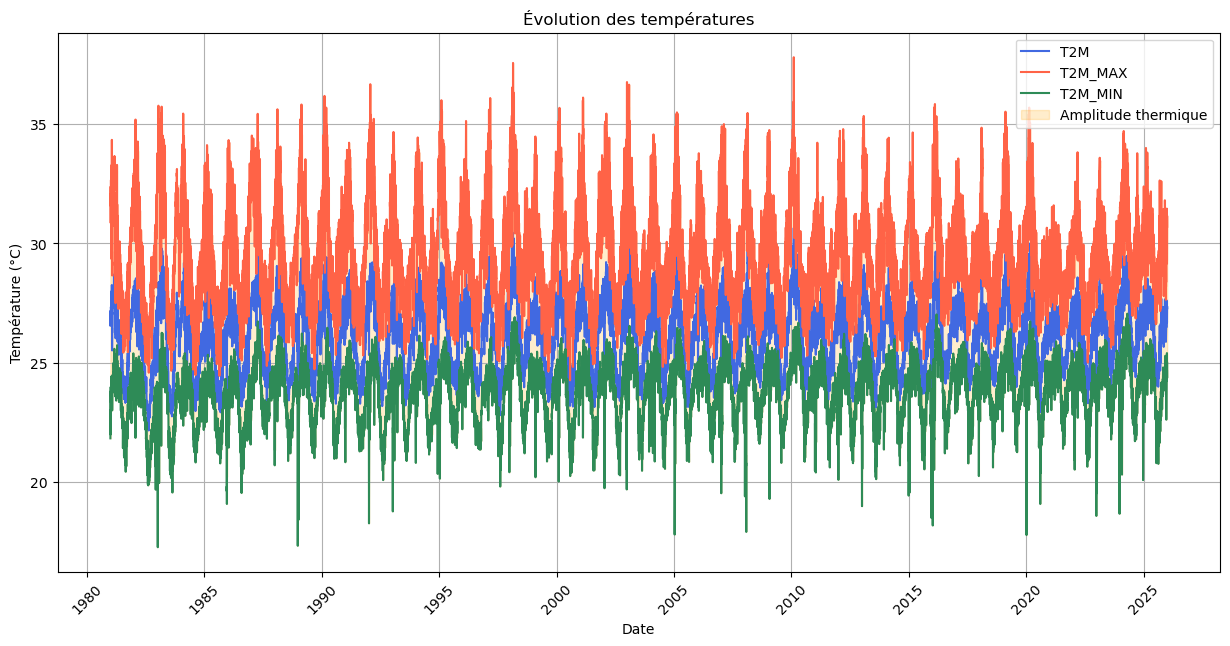

In [13]:
y1= df["T2M"]
y2= df["T2M_MAX"]
y3= df["T2M_MIN"]
x = df["date"]
plt.figure(figsize=(15,7))
plt.plot(x,y1 ,color="royalblue",label="T2M")
plt.plot(x,y2,color="tomato",label="T2M_MAX")
plt.plot(x,y3,color="seagreen",label="T2M_MIN")

plt.fill_between(x, y3, y2,
                 color="orange",
                 alpha=0.2,
                 label="Amplitude thermique")
plt.xticks(rotation=45)

plt.title("Évolution des températures")
plt.xlabel("Date")
plt.ylabel("Température (°C)")
plt.legend()
plt.grid(True)
plt.show()

# Humidité du sol

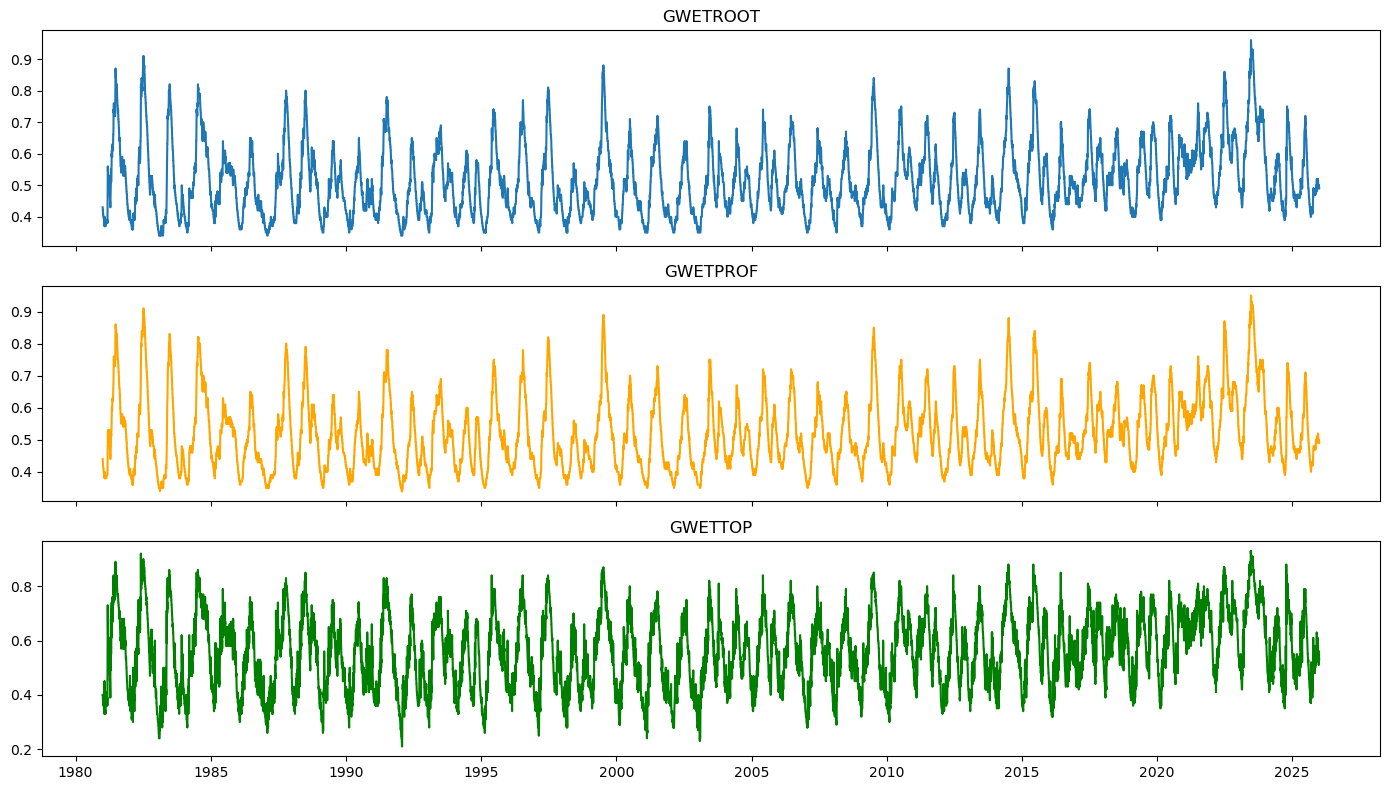

In [20]:
fig, axs = plt.subplots(3, 1,
                        figsize=(14,8),
                        sharex=True)

axs[0].plot(df["date"], df["GWETROOT"])
axs[0].set_title("GWETROOT")

axs[1].plot(df["date"], df["GWETPROF"],
            color="orange")
axs[1].set_title("GWETPROF")

axs[2].plot(df["date"], df["GWETTOP"],
            color="green")
axs[2].set_title("GWETTOP")

plt.tight_layout()
plt.show()

# Précipitations

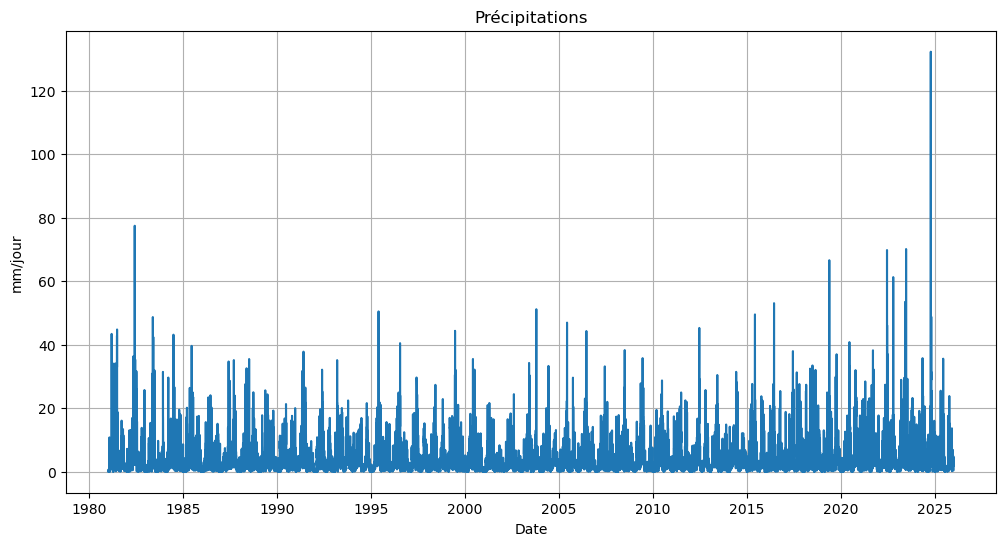

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(df["date"], df["PRECTOTCORR"])


plt.title("Précipitations")
plt.xlabel("Date")
plt.ylabel("mm/jour")
plt.grid()
plt.show()

In [25]:
max_prec = df["PRECTOTCORR"].max()

print(f"Précipitation maximale : {max_prec} mm/j")

Précipitation maximale : 132.25 mm/j


# Humidité de l'air

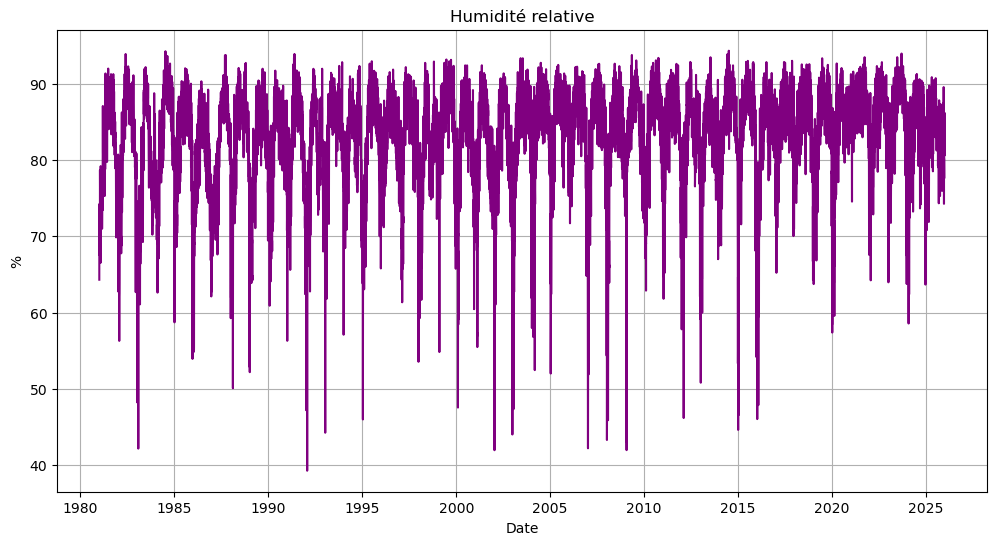

In [26]:
plt.figure(figsize=(12,6))

plt.plot(df["date"], df["RH2M"],
         color="purple")

plt.title("Humidité relative")
plt.xlabel("Date")
plt.ylabel("%")
plt.grid()
plt.show()

# Rayonnement solaire

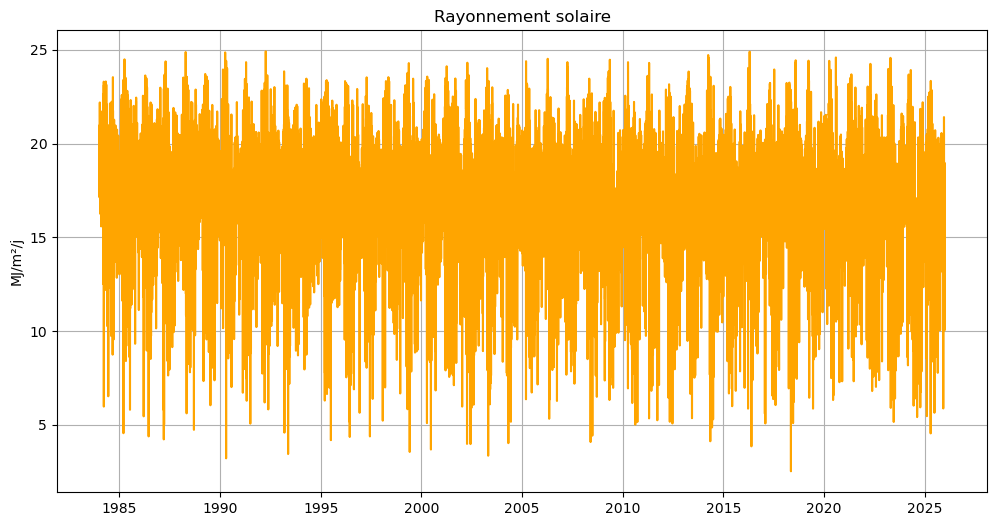

In [29]:
plt.figure(figsize=(12,6))

plt.plot(df["date"],
         df["ALLSKY_SFC_SW_DWN"],
         color="orange")

plt.title("Rayonnement solaire")
plt.ylabel("MJ/m²/j")
plt.grid()
plt.show()

# Évaporation et évapotranspiration

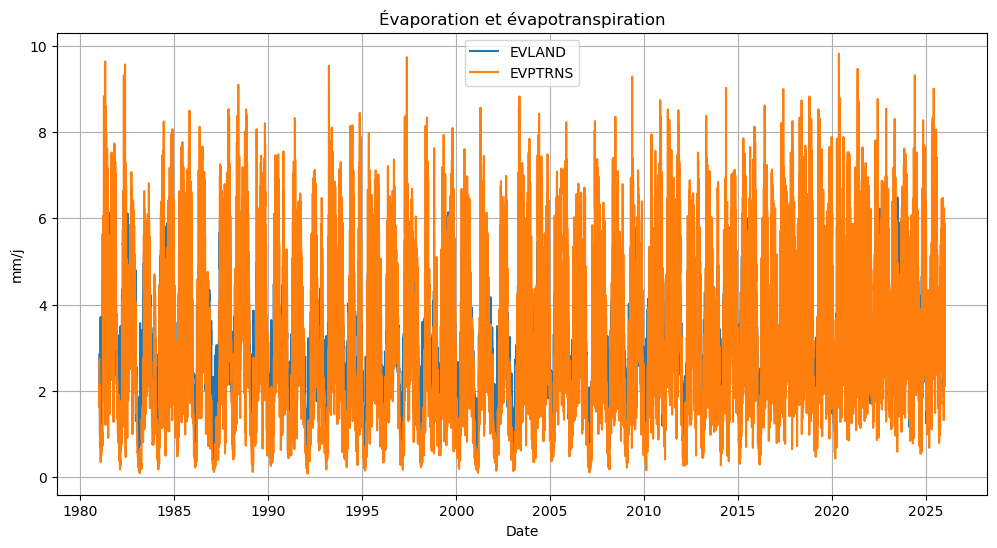

In [30]:
plt.figure(figsize=(12,6))

plt.plot(df["date"],
         df["EVLAND"],
         label="EVLAND")

plt.plot(df["date"],
         df["EVPTRNS"],
         label="EVPTRNS")

plt.title("Évaporation et évapotranspiration")
plt.xlabel("Date")
plt.ylabel("mm/j")
plt.legend()
plt.grid()
plt.show()

# Correlation

# 4.indicateurs